JSON has been generated and saved to file.
Aim Section Peaks: [0.0, 0.0, 0.0, 7.008828542384492, 10.918481340838305, 14.994546829908273, 13.863677599327959, 14.333370711941523, 17.00544727018754, 14.80167586750165, 56.46367861636142, 61.93762420741429, 89.85906445812074, 54.86815873709996, 68.10527481694876, 89.31873523012918, 82.07643287005382, 79.63485572601371, 54.90565594978746, 49.79364598277386, 84.45193649890096, 84.78357326994877, 94.66155618519578, 73.78480917843532, 69.11796340478125, 79.94879049736649, 45.309424722484025, 21.214121494636956, 9.932568191842291, 4.650482977130965, 46.1228106532259, 29.550977197703737, 69.47185938772941, 69.20876591757627, 70.00925959682174, 71.67278682796947, 51.91463505061448, 105.95422723978753, 79.6360766072085, 73.9878896275666, 119.37121419665694, 97.74950285995119, 57.18201940895292, 52.935599182205976, 31.51708991626369, 76.58076502436172, 61.27888800732333, 77.57208655297943, 74.17235516582208, 125.9054216469581, 138.112789137628, 117.

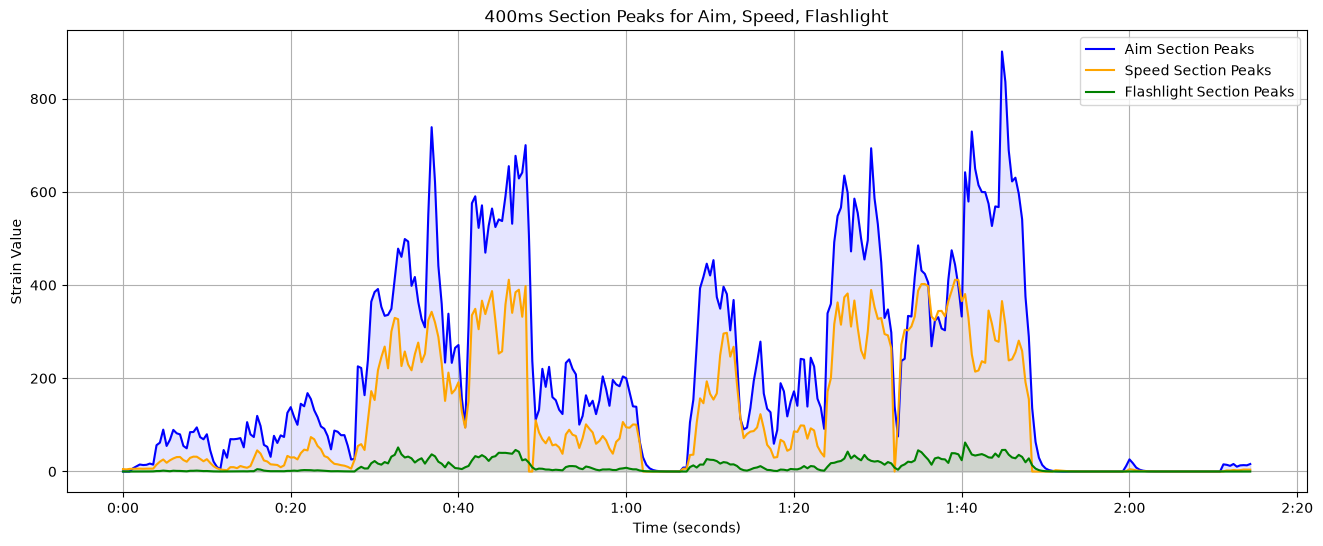

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import rosu_pp_py as rosu
import math
from classes.BeatmapCollect import BeatmapCollect
from classes.BeatmapAnalyze import BeatmapAnalyze, ScoreAnalyze

MAP_ID = "5722291"  # Replace with your .osu file path

beatmap_collect = BeatmapCollect(MAP_ID)
beatmap_collect.load_beatmap()
beatmap_collect.save_to_file(f"{MAP_ID}.osu")

beatmap_analyze = BeatmapAnalyze(map_file_path=f"{MAP_ID}.osu", mods=BeatmapAnalyze.mods_to_int("DT"))  # Replace with the desired mods
beatmap_data = beatmap_analyze.load_beatmap()
aim_section_peaks = beatmap_data['aim_section_peaks']
speed_section_peaks = beatmap_data['speed_section_peaks']
flashlight_section_peaks = beatmap_data['flashlight_section_peaks']

beatmap_analyze.save_to_json(f"{MAP_ID}_section_peaks.json")
print("JSON has been generated and saved to file.")

print("Aim Section Peaks:", aim_section_peaks)
print("Speed Section Peaks:", speed_section_peaks)
print("Flashlight Section Peaks:", flashlight_section_peaks)
# # Plot every 400ms section peak for Aim and Speed and Flashlight and Rhythm and Stamina

def plot_section_peaks(aim_peaks, speed_peaks, flashlight_peaks):
    # Generate time axis in seconds (each bucket is 400ms / 0.4s)
    time_sec = np.arange(len(aim_peaks)) * 0.4

    plt.figure(figsize=(16, 6))
    plt.plot(time_sec, aim_peaks, label='Aim Section Peaks', color='blue')
    plt.plot(time_sec, speed_peaks, label='Speed Section Peaks', color='orange')
    plt.plot(time_sec, flashlight_peaks, label='Flashlight Section Peaks', color='green')

    plt.fill_between(time_sec, aim_peaks, alpha=0.1, color='blue')
    plt.fill_between(time_sec, speed_peaks, alpha=0.1, color='orange')
    plt.fill_between(time_sec, flashlight_peaks, alpha=0.1, color='green')

    # Optional: Format x-axis as mm:ss
    formatter = plt.FuncFormatter(lambda s, x: f"{int(s//60)}:{int(s%60):02d}")
    plt.gca().xaxis.set_major_formatter(formatter)

    plt.xlabel('Time (seconds)')
    
    plt.ylabel('Strain Value')
    plt.title('400ms Section Peaks for Aim, Speed, Flashlight')
    plt.legend()
    plt.grid()

    plt.show()

plot_section_peaks(aim_section_peaks, speed_section_peaks, flashlight_section_peaks)


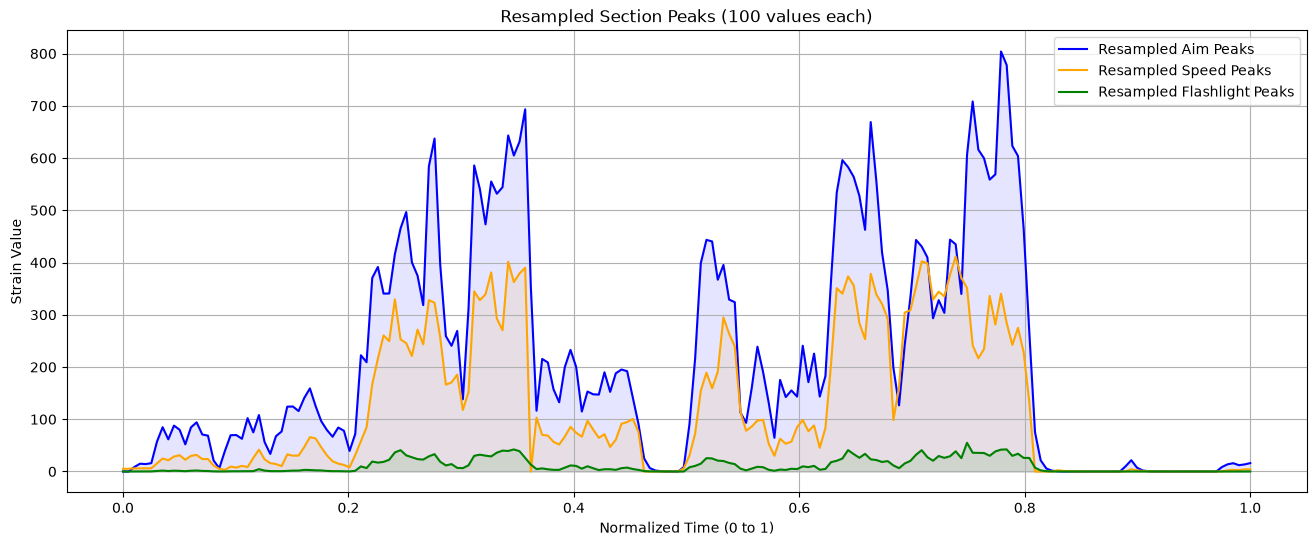

In [6]:
TARGET_LENGTH = 200  # Desired length for resampled arrays

def resample_strain(strain_array, target_length=TARGET_LENGTH):
    original_indices = np.linspace(0, 1, len(strain_array))
    target_indices = np.linspace(0, 1, target_length)
    # Stretch or compress the array to exactly 100 values
    return np.interp(target_indices, original_indices, strain_array)

# Resample the section peaks to 100 values each
aim_resampled = resample_strain(aim_section_peaks)
speed_resampled = resample_strain(speed_section_peaks)
flashlight_resampled = resample_strain(flashlight_section_peaks)

#plot the resampled section peaks
def plot_resampled_peaks(aim_resampled, speed_resampled, flashlight_resampled):
    time_sec = np.linspace(0, 1, TARGET_LENGTH)  # Normalized time axis for resampled data

    plt.figure(figsize=(16, 6))
    plt.plot(time_sec, aim_resampled, label='Resampled Aim Peaks', color='blue')
    plt.plot(time_sec, speed_resampled, label='Resampled Speed Peaks', color='orange')
    plt.plot(time_sec, flashlight_resampled, label='Resampled Flashlight Peaks', color='green')

    plt.fill_between(time_sec, aim_resampled, alpha=0.1, color='blue')
    plt.fill_between(time_sec, speed_resampled, alpha=0.1, color='orange')
    plt.fill_between(time_sec, flashlight_resampled, alpha=0.1, color='green')

    plt.xlabel('Normalized Time (0 to 1)')
    plt.ylabel('Strain Value')
    plt.title('Resampled Section Peaks (100 values each)')
    plt.legend()
    plt.grid()

    plt.show()

plot_resampled_peaks(aim_resampled, speed_resampled, flashlight_resampled)